# Study 2A: Age Estimation from Children's Speech and Text (MyST Corpus)

This notebook analyzes the Study 2A run on the MyST corpus. The data were collected on the pinned `google-genai 2.0.0` setup, so the Gemini estimates are reliable. The notebook reads the saved result CSVs and reports the age estimates, the audio versus text comparison, and the binary threshold classifications.

## 1. Setup

In [1]:
# Environment report. This is an analysis notebook that reads the Study 2A result CSVs.
# It does not call any model, so it reports the versions of the libraries it actually uses
# rather than asserting the data-collection pins. The data were collected under the pinned
# google-genai 2.0.0 environment described in the methods.
import importlib.metadata as ilm

for pkg in ['pandas', 'numpy', 'scipy', 'matplotlib', 'seaborn']:
    try:
        print(f'{pkg}: {ilm.version(pkg)}')
    except ilm.PackageNotFoundError:
        print(f'{pkg}: not installed')

import pandas as pd
import numpy as np
import re
import warnings
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

warnings.filterwarnings('ignore')
sns.set_theme(style='whitegrid', palette='muted', font_scale=1.1)
plt.rcParams['figure.dpi'] = 120

pandas: 2.0.2
numpy: 1.24.3
scipy: 1.15.3
matplotlib: 3.8.0
seaborn: 0.13.2


## 2. Load Data

In [2]:
df = pd.read_csv('study2a_results.csv')

print(f'Total rows: {len(df):,}')
print(f'Conditions: {df["condition"].value_counts().to_dict()}')
print(f'Models: {df["model"].value_counts().to_dict()}')
print(f'Questions: {df["question"].value_counts().to_dict()}')
print(f'Students: {df["student_id"].nunique()}')

MODELS = {
    'gemini': 'Gemini 2.5 Flash',
    'gpt4o': 'GPT-4o',
    'nemotron': 'Nemotron 3 Nano Omni',
}

Total rows: 13,500
Conditions: {'audio': 6750, 'text': 6750}
Models: {'gemini': 4500, 'gpt4o': 4500, 'nemotron': 4500}
Questions: {'q1_over_13': 4500, 'q2_over_18': 4500, 'q3_age': 4500}
Students: 250


## 3. Diagnostics

In [3]:
print('RESPONSE DIAGNOSTICS')
print('=' * 70)

for cond in ['audio', 'text']:
    print(f'\n--- {cond.upper()} ---')
    for mk in ['gemini', 'gpt4o', 'nemotron']:
        sub = df[(df['model'] == mk) & (df['condition'] == cond)]
        errs = sub[sub['response'].str.startswith('ERROR', na=False)]
        refs = sub[sub['response'].str.contains(
            "sorry|can't estimate|can't determine|can't identify|can't analyze",
            case=False, na=False)]
        ok = sub[~sub.index.isin(errs.index) & ~sub.index.isin(refs.index)]
        print(f'  {MODELS[mk]:.<30s} Errors:{len(errs):>5d}  '
              f'Refusals:{len(refs):>5d}  Answers:{len(ok):>5d}')

RESPONSE DIAGNOSTICS

--- AUDIO ---
  Gemini 2.5 Flash.............. Errors:  265  Refusals:    0  Answers: 1985
  GPT-4o........................ Errors:  260  Refusals:   49  Answers: 1941
  Nemotron 3 Nano Omni.......... Errors:  680  Refusals:    0  Answers: 1570

--- TEXT ---
  Gemini 2.5 Flash.............. Errors:    2  Refusals:    5  Answers: 2243
  GPT-4o........................ Errors:    0  Refusals:    0  Answers: 2250
  Nemotron 3 Nano Omni.......... Errors:    0  Refusals:    1  Answers: 2249


## 4. Parse Responses

In [4]:
def parse_yn(r):
    r = str(r)
    if r.startswith('ERROR'): return 'ERROR'
    if re.search(r"sorry|can't", r, re.I): return 'REFUSED'
    u = r.strip().upper()
    if u.startswith('YES'): return 'YES'
    if u.startswith('NO'): return 'NO'
    fl = u.split('\n')[0]
    if 'YES' in fl and 'NO' not in fl: return 'YES'
    if 'NO' in fl and 'YES' not in fl: return 'NO'
    return 'UNCLEAR'

def parse_age(r):
    r = str(r)
    if r.startswith('ERROR'): return None
    if re.search(r"sorry|can't estimate|can't determine|can't identify|can't analyze", r, re.I):
        return None
    m = re.search(r'[Ee]stimated\s+[Aa]ge[:\s]+(\d+)', r)
    if m: return int(m.group(1))
    m = re.search(r'(\d+)\s*-\s*(\d+)\s*years', r)
    if m: return (int(m.group(1)) + int(m.group(2))) / 2
    nums = re.findall(r'\d+', r.split('\n')[0])
    return int(nums[0]) if nums else None

q1 = df[df['question'] == 'q1_over_13'].copy()
q1['pred'] = q1['response'].apply(parse_yn)

q2 = df[df['question'] == 'q2_over_18'].copy()
q2['pred'] = q2['response'].apply(parse_yn)

q3 = df[df['question'] == 'q3_age'].copy()
q3['pred_age'] = q3['response'].apply(parse_age)
valid_q3 = q3.dropna(subset=['pred_age'])

print('Parsed Q3:')
for cond in ['audio', 'text']:
    print(f'\n  {cond.upper()}:')
    for mk in ['gemini', 'gpt4o', 'nemotron']:
        s = valid_q3[(valid_q3['model'] == mk) & (valid_q3['condition'] == cond)]
        print(f'    {MODELS[mk]}: {len(s)} valid from {s["student_id"].nunique()} students')

Parsed Q3:

  AUDIO:
    Gemini 2.5 Flash: 660 valid from 220 students
    GPT-4o: 654 valid from 221 students
    Nemotron 3 Nano Omni: 524 valid from 175 students

  TEXT:
    Gemini 2.5 Flash: 748 valid from 250 students
    GPT-4o: 750 valid from 250 students
    Nemotron 3 Nano Omni: 750 valid from 250 students


## 5. Binary Classification (Q1, Q2)

All students are grades 3-5 (~ages 8-11), so the correct answer is NO for both questions.

In [5]:
for label, qdf in [("Q1: Over 13?", q1), ("Q2: Over 18?", q2)]:
    print(label)
    print('=' * 60)
    print(f'{"Model":<25s} {"Audio % YES":>12s} {"Text % YES":>12s}')
    print('-' * 60)

    for mk in ['gemini', 'gpt4o', 'nemotron']:
        row = f'{MODELS[mk]:<25s}'
        for cond in ['audio', 'text']:
            s = qdf[(qdf['model'] == mk) & (qdf['condition'] == cond)]
            valid = s[s['pred'].isin(['YES', 'NO'])]
            if len(valid) > 0:
                yes_pct = (valid['pred'] == 'YES').mean() * 100
                row += f'{yes_pct:>11.1f}%'
            else:
                row += f'{"n/a":>12s}'
        print(row)
    print()

Q1: Over 13?
Model                      Audio % YES   Text % YES
------------------------------------------------------------
Gemini 2.5 Flash                11.6%       51.9%
GPT-4o                           2.5%       51.7%
Nemotron 3 Nano Omni             5.0%        1.6%

Q2: Over 18?
Model                      Audio % YES   Text % YES
------------------------------------------------------------
Gemini 2.5 Flash                 1.5%       29.8%
GPT-4o                           0.2%        7.7%
Nemotron 3 Nano Omni             0.8%        1.5%



## 6. Age Estimation Overview (Q3)

In [6]:
print('AGE ESTIMATION SUMMARY')
print('Expected range: ~8-11 years (grades 3-5)')
print('=' * 70)
print(f'{"Model":<25s} {"Cond":<7s} {"n_stu":>6s} {"Mean":>6s} {"Med":>5s} '
      f'{"SD":>5s} {"Range":>8s} {"In 8-11":>8s}')
print('-' * 70)

for mk in ['gemini', 'gpt4o', 'nemotron']:
    for cond in ['audio', 'text']:
        s = valid_q3[(valid_q3['model'] == mk) & (valid_q3['condition'] == cond)]
        if len(s) == 0:
            continue
        ages = s['pred_age']
        n_stu = s['student_id'].nunique()
        in_range = ((ages >= 8) & (ages <= 11)).mean() * 100
        print(f'{MODELS[mk]:<25s} {cond:<7s} {n_stu:>6d} {ages.mean():>6.1f} '
              f'{ages.median():>5.1f} {ages.std():>5.1f} '
              f'{ages.min():.0f}-{ages.max():.0f}{"":<3s} {in_range:>6.0f}%')

AGE ESTIMATION SUMMARY
Expected range: ~8-11 years (grades 3-5)
Model                     Cond     n_stu   Mean   Med    SD    Range  In 8-11
----------------------------------------------------------------------
Gemini 2.5 Flash          audio      220    9.2   9.0   1.7 5-20        78%
Gemini 2.5 Flash          text       250   11.3  10.0   4.4 3-40        55%
GPT-4o                    audio      221    8.9   9.0   1.4 6-18        80%
GPT-4o                    text       250    9.9  10.0   2.3 4-20        63%
Nemotron 3 Nano Omni      audio      175    7.9   8.0   1.7 4-15        56%
Nemotron 3 Nano Omni      text       250   14.9  12.0   7.8 4-65        28%


## 7. Audio vs. Text Comparison

The core bottleneck question: does the acoustic signal shift the model's age estimate relative to text alone? For each student, we compare the mean age estimate from audio to the mean from text.

In [7]:
student_means = valid_q3.groupby(['student_id', 'model', 'condition'])['pred_age'].mean().reset_index()

print('AUDIO vs. TEXT DELTA')
print('Negative delta = audio estimates younger than text')
print('=' * 70)

deltas = {}

for mk in ['gemini', 'gpt4o', 'nemotron']:
    audio_m = student_means[(student_means['model'] == mk) & (student_means['condition'] == 'audio')]
    text_m = student_means[(student_means['model'] == mk) & (student_means['condition'] == 'text')]
    merged = audio_m[['student_id', 'pred_age']].merge(
        text_m[['student_id', 'pred_age']], on='student_id', suffixes=('_audio', '_text'))
    merged['delta'] = merged['pred_age_audio'] - merged['pred_age_text']
    deltas[mk] = merged

    t, p = stats.ttest_1samp(merged['delta'], 0)
    sig = '***' if p < .001 else '**' if p < .01 else '*' if p < .05 else 'n.s.'

    print(f'\n{MODELS[mk]} ({len(merged)} students):')
    print(f'  Audio mean: {merged["pred_age_audio"].mean():.1f}')
    print(f'  Text mean:  {merged["pred_age_text"].mean():.1f}')
    print(f'  Delta:      {merged["delta"].mean():+.1f} years')
    print(f'  t={t:.2f}, p={p:.6f} {sig}')

AUDIO vs. TEXT DELTA
Negative delta = audio estimates younger than text

Gemini 2.5 Flash (220 students):
  Audio mean: 9.2
  Text mean:  11.3
  Delta:      -2.2 years
  t=-8.65, p=0.000000 ***

GPT-4o (221 students):
  Audio mean: 8.9
  Text mean:  9.8
  Delta:      -1.0 years
  t=-7.86, p=0.000000 ***

Nemotron 3 Nano Omni (175 students):
  Audio mean: 7.9
  Text mean:  14.8
  Delta:      -7.0 years
  t=-14.47, p=0.000000 ***


## 8. Relationship to the Kids VA studies

Study 2A runs on the MyST corpus. It uses 250 children in grades 3 to 5 with about 30 seconds of conversational speech each. The Kids VA studies use 28 children aged 5 to 10 with about 6 seconds each. Placing the two side by side tests whether the corrected conclusion holds across different corpora, clip lengths, and recording conditions. The comparison is one of consistency rather than improvement. The corrected Kids VA results and these MyST results both show accurate age estimation from audio.

In [8]:
# Cross-corpus consistency, audio condition, Q3.
# The corrected Kids VA (Study 1a) Gemini baseline is about 6.7 for ages 5 to 10.
# That figure comes from the pinned google-genai 2.0.0 rerun, not this notebook.
# The earlier ~35 estimate was a google-genai 0.4.0 double-encoding defect.
KIDS_VA_GEMINI_CORRECTED = 6.7

print('CROSS-CORPUS CONSISTENCY (audio condition, Q3)')
print('=' * 60)
print()
print('Study 2A (MyST, 250 children, 30s conversational):')
for mk in ['gemini', 'gpt4o', 'nemotron']:
    s = valid_q3[(valid_q3['model'] == mk) & (valid_q3['condition'] == 'audio')]
    if len(s) > 0:
        tot = df[(df['model'] == mk) & (df['condition'] == 'audio')]
        err_pct = tot['response'].str.startswith('ERROR', na=False).mean() * 100
        ref_pct = tot['response'].str.contains("sorry|can't", case=False, na=False).mean() * 100
        print(f'  {MODELS[mk]:.<25s} mean={s["pred_age"].mean():.1f}, '
              f'errors={err_pct:.0f}%, refusals={ref_pct:.0f}%')
print()
print('Corrected Kids VA (Study 1a, 28 children, 6s scripted):')
print(f'  Gemini:   mean estimate ~{KIDS_VA_GEMINI_CORRECTED} for ages 5 to 10 (accurate)')
print('  Nemotron: compresses toward the young end, 5 to 7')
print('  GPT:      successor model refuses nearly all speakers')
print()
print('Reading:')
print('  Gemini estimates children accurately on both corpora.')
print('  The earlier Kids VA ~35 was a software defect, not a corpus effect.')
print('  This larger MyST sample reinforces the corrected conclusion at scale.')

CROSS-CORPUS CONSISTENCY (audio condition, Q3)

Study 2A (MyST, 250 children, 30s conversational):
  Gemini 2.5 Flash......... mean=9.2, errors=12%, refusals=0%
  GPT-4o................... mean=8.9, errors=12%, refusals=2%
  Nemotron 3 Nano Omni..... mean=7.9, errors=30%, refusals=0%

Corrected Kids VA (Study 1a, 28 children, 6s scripted):
  Gemini:   mean estimate ~6.7 for ages 5 to 10 (accurate)
  Nemotron: compresses toward the young end, 5 to 7
  GPT:      successor model refuses nearly all speakers

Reading:
  Gemini estimates children accurately on both corpora.
  The earlier Kids VA ~35 was a software defect, not a corpus effect.
  This larger MyST sample reinforces the corrected conclusion at scale.


## 9. Visualization

### 9a. Age estimate distributions by model and condition

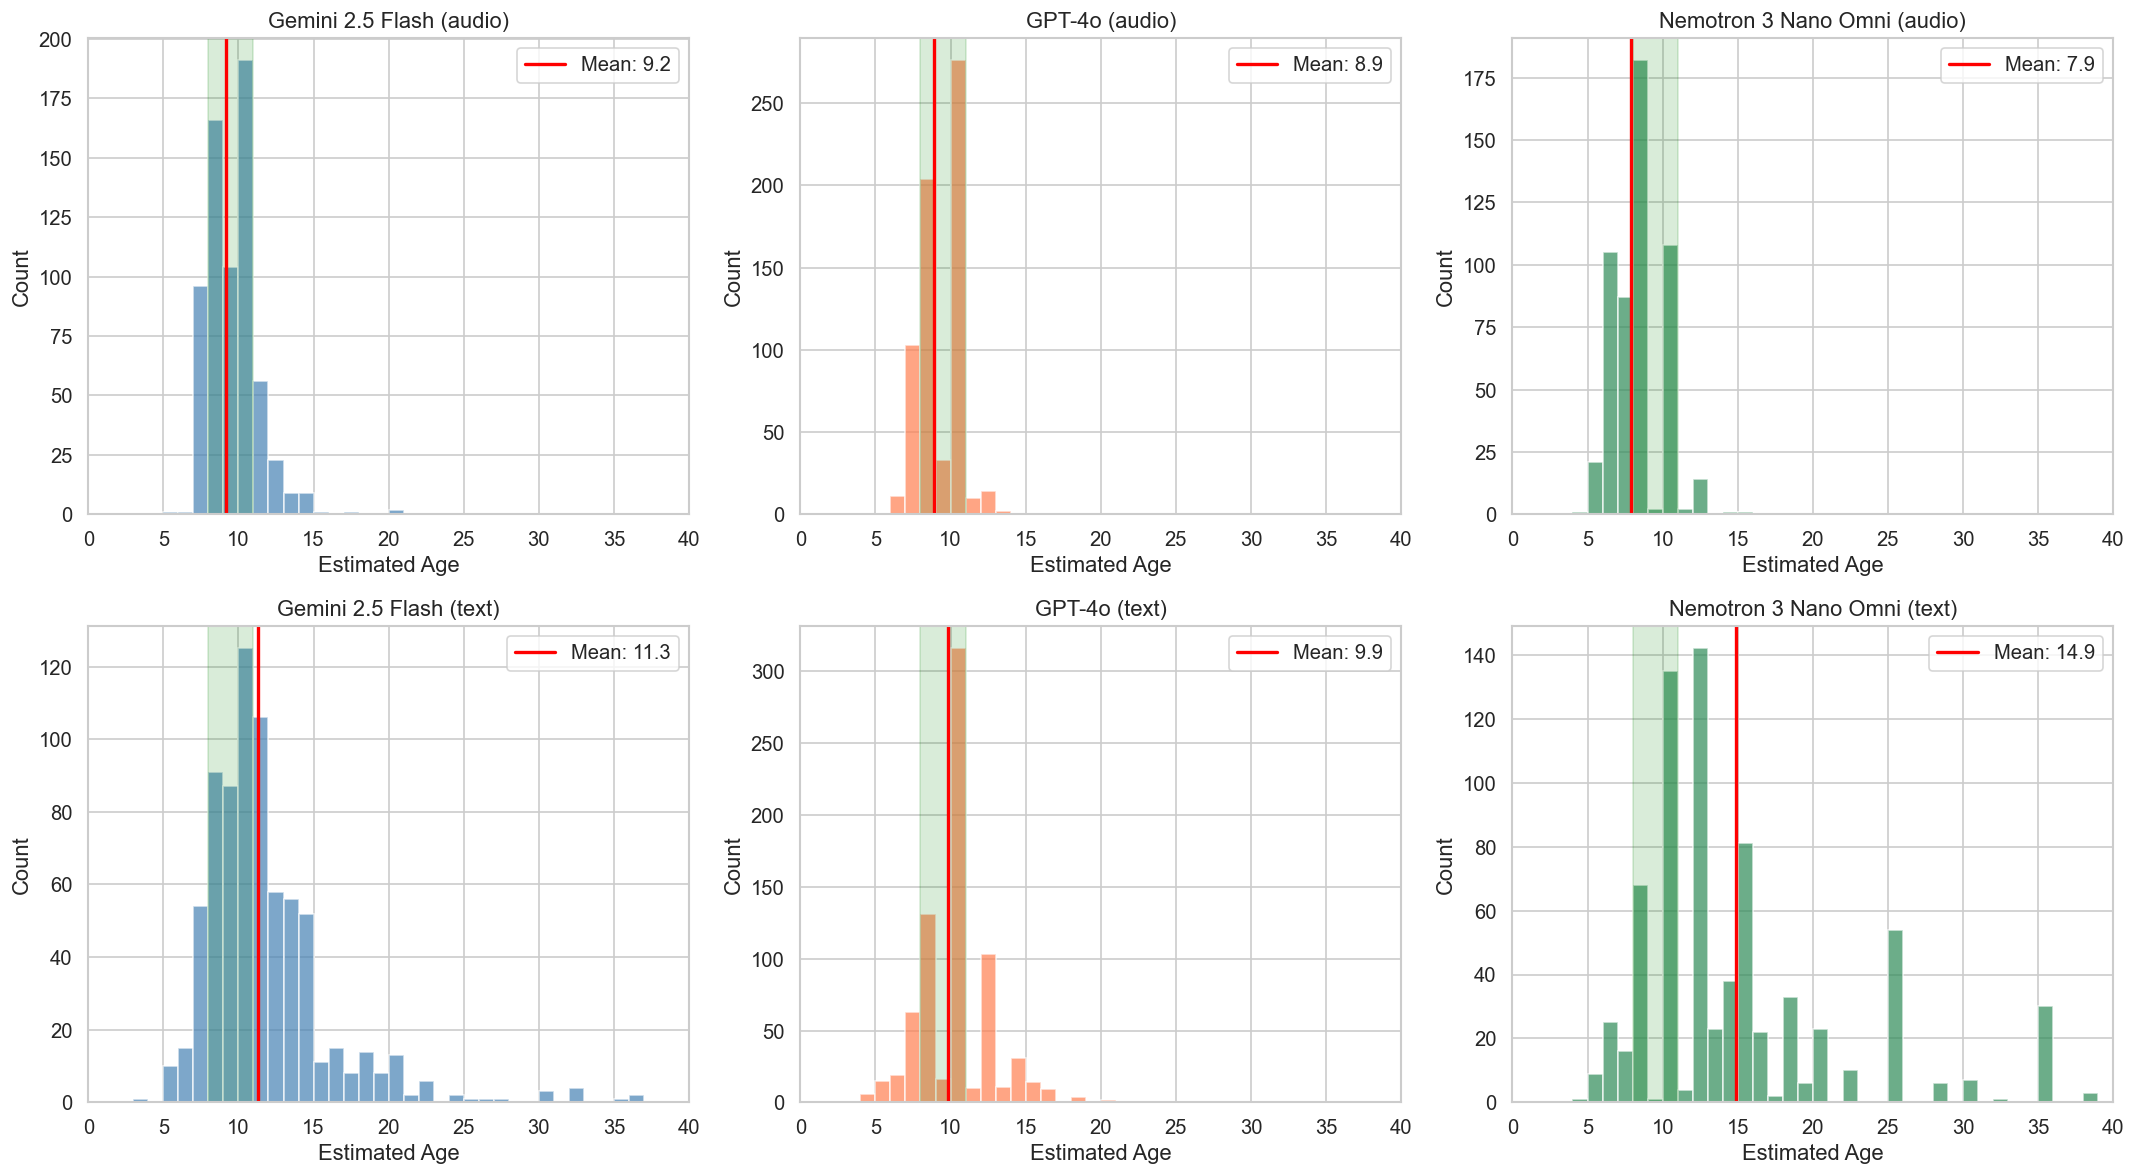

In [9]:
colors = {'gemini': 'steelblue', 'gpt4o': 'coral', 'nemotron': 'seagreen'}

fig, axes = plt.subplots(2, 3, figsize=(18, 10))

for i, mk in enumerate(['gemini', 'gpt4o', 'nemotron']):
    for j, cond in enumerate(['audio', 'text']):
        ax = axes[j][i]
        s = valid_q3[(valid_q3['model'] == mk) & (valid_q3['condition'] == cond)]
        if len(s) > 0:
            ax.hist(s['pred_age'], bins=range(0, 50, 1), color=colors[mk],
                    alpha=0.7, edgecolor='white')
            ax.axvspan(8, 11, alpha=0.15, color='green')
            ax.axvline(s['pred_age'].mean(), color='red', linestyle='-', lw=2,
                      label=f'Mean: {s["pred_age"].mean():.1f}')
            ax.legend()
        ax.set_xlabel('Estimated Age')
        ax.set_ylabel('Count')
        ax.set_title(f'{MODELS[mk]} ({cond})')
        ax.set_xlim(0, 40)

plt.tight_layout()
plt.savefig('study2_age_distributions.png', dpi=150, bbox_inches='tight')
plt.show()

### 9b. Audio vs. text delta by model

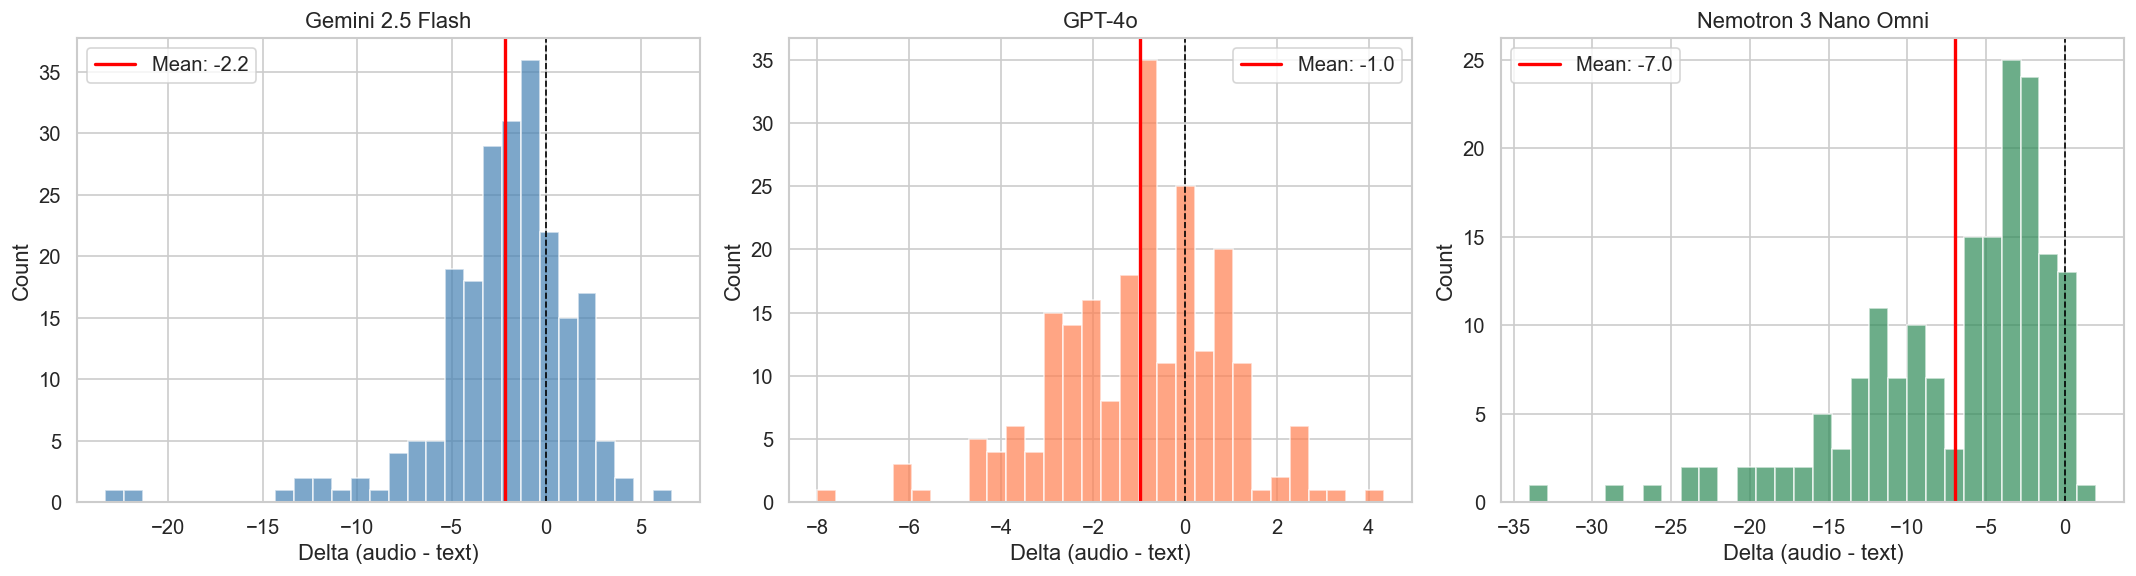

In [10]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

for i, mk in enumerate(['gemini', 'gpt4o', 'nemotron']):
    ax = axes[i]
    if mk in deltas:
        d = deltas[mk]['delta']
        ax.hist(d, bins=30, color=colors[mk], alpha=0.7, edgecolor='white')
        ax.axvline(x=0, color='black', linestyle='--', lw=1)
        ax.axvline(x=d.mean(), color='red', linestyle='-', lw=2,
                  label=f'Mean: {d.mean():+.1f}')
        ax.legend()
    ax.set_xlabel('Delta (audio - text)')
    ax.set_ylabel('Count')
    ax.set_title(MODELS[mk])

plt.tight_layout()
plt.savefig('study2_audio_text_delta.png', dpi=150, bbox_inches='tight')
plt.show()

### 9c. Binary classification rates

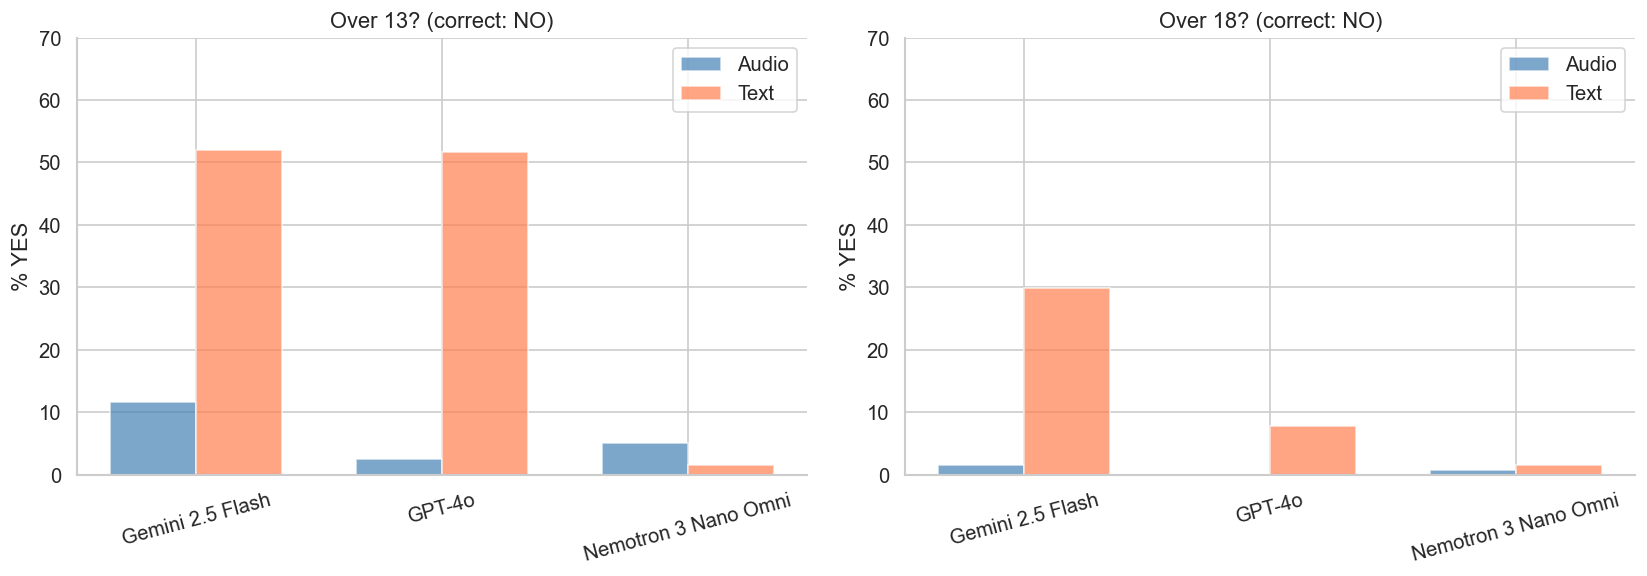

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
model_order = ['gemini', 'gpt4o', 'nemotron']
x = np.arange(len(model_order))
width = 0.35

for idx, (label, qdf) in enumerate([("Over 13?", q1), ("Over 18?", q2)]):
    ax = axes[idx]
    audio_rates = []
    text_rates = []
    for mk in model_order:
        for cond, rates in [('audio', audio_rates), ('text', text_rates)]:
            s = qdf[(qdf['model'] == mk) & (qdf['condition'] == cond)]
            valid = s[s['pred'].isin(['YES', 'NO'])]
            rate = (valid['pred'] == 'YES').mean() * 100 if len(valid) > 0 else 0
            rates.append(rate)

    ax.bar(x - width/2, audio_rates, width, label='Audio', color='steelblue', alpha=0.7)
    ax.bar(x + width/2, text_rates, width, label='Text', color='coral', alpha=0.7)
    ax.set_xticks(x)
    ax.set_xticklabels([MODELS[mk] for mk in model_order], rotation=15)
    ax.set_ylabel('% YES')
    ax.set_title(f'{label} (correct: NO)')
    ax.legend()
    ax.set_ylim(0, 70)

sns.despine()
plt.tight_layout()
plt.savefig('study2_binary_classification.png', dpi=150, bbox_inches='tight')
plt.show()

### 9d. Model comparison (box plots)

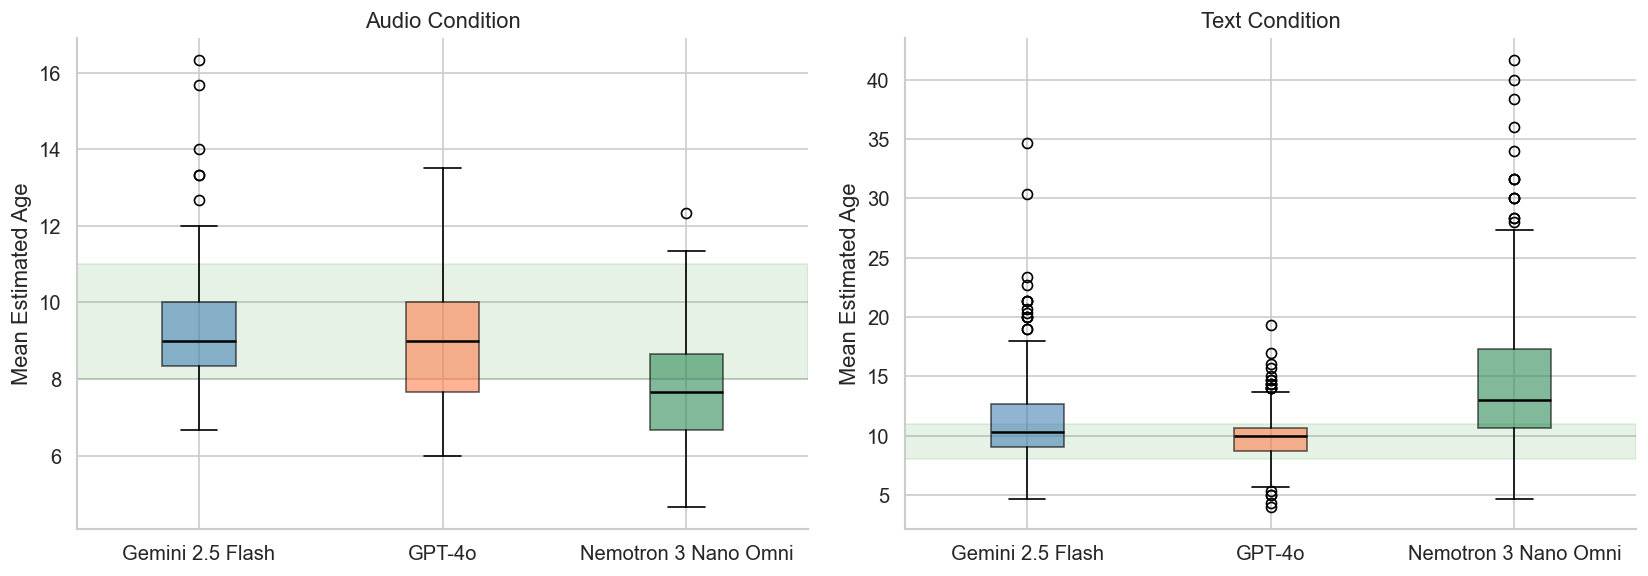

In [12]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

for i, cond in enumerate(['audio', 'text']):
    ax = axes[i]
    data = []
    labels = []
    plot_colors = []
    for mk in ['gemini', 'gpt4o', 'nemotron']:
        s = valid_q3[(valid_q3['model'] == mk) & (valid_q3['condition'] == cond)]
        if len(s) > 0:
            sm = s.groupby('student_id')['pred_age'].mean()
            data.append(sm.values)
            labels.append(MODELS[mk])
            plot_colors.append(colors[mk])

    bp = ax.boxplot(data, labels=labels, patch_artist=True,
                     medianprops={'color': 'black', 'linewidth': 1.5})
    for patch, c in zip(bp['boxes'], plot_colors):
        patch.set_facecolor(c)
        patch.set_alpha(0.6)

    ax.axhspan(8, 11, alpha=0.1, color='green')
    ax.set_ylabel('Mean Estimated Age')
    ax.set_title(f'{cond.title()} Condition')

sns.despine()
plt.tight_layout()
plt.savefig('study2_model_boxplots.png', dpi=150, bbox_inches='tight')
plt.show()

## 10. Sample Reasoning (Q3)

In [ ]:
for cond in ['audio', 'text']:
    print(f'\n{"=" * 60}')
    print(f'{cond.upper()} CONDITION')
    print(f'{"=" * 60}')
    for mk in ['gemini', 'gpt4o', 'nemotron']:
        s = q3[(q3['model'] == mk) & (q3['condition'] == cond)]
        answered = s[s['pred_age'].notna()]
        if len(answered) > 0:
            row = answered.iloc[0]
            print(f'\n  {MODELS[mk]} [{row["student_id"]}]:')
            print(f'  {row["response"][:300]}')
        else:
            print(f'\n  {MODELS[mk]}: no valid responses')

## 11. Error Analysis

In [14]:
print('ERROR BREAKDOWN (audio condition)')
print('=' * 60)

for mk in ['gemini', 'gpt4o', 'nemotron']:
    audio = df[(df['model'] == mk) & (df['condition'] == 'audio')]
    errs = audio[audio['response'].str.startswith('ERROR', na=False)]
    if len(errs) > 0:
        print(f'\n{MODELS[mk]}: {len(errs)} errors ({100*len(errs)/len(audio):.0f}%)')
        # Sample unique error messages
        unique_errs = errs['response'].str[:100].value_counts().head(3)
        for msg, count in unique_errs.items():
            print(f'  [{count}x] {msg}')
    else:
        print(f'\n{MODELS[mk]}: 0 errors')

ERROR BREAKDOWN (audio condition)

Gemini 2.5 Flash: 265 errors (12%)
  [265x] ERROR: 429 RESOURCE_EXHAUSTED. {'error': {'code': 429, 'message': 'You exceeded your current quota, 

GPT-4o: 260 errors (12%)
  [258x] ERROR: Error code: 429 - {'error': {'message': 'Rate limit reached for gpt-4o-audio-preview (for lim
  [2x] ERROR: Request timed out.

Nemotron 3 Nano Omni: 680 errors (30%)
  [675x] ERROR: Client error '403 Forbidden' for url 'https://rest.fal.ai/storage/auth/token?storage_type=fal
  [5x] ERROR: [{'loc': ['body', 'prompt'], 'msg': 'The content could not be processed because it contained 


## 12. Save Parsed Results

In [15]:
valid_q3.to_csv('study2a_q3_parsed.csv', index=False)

student_means.to_csv('study2a_student_means.csv', index=False)

q1_rates = q1[q1['pred'].isin(['YES', 'NO'])].groupby(
    ['model', 'condition']).apply(
    lambda x: (x['pred'] == 'YES').mean()).reset_index(name='pct_yes')
q1_rates.to_csv('study2a_q1_over13.csv', index=False)

q2_rates = q2[q2['pred'].isin(['YES', 'NO'])].groupby(
    ['model', 'condition']).apply(
    lambda x: (x['pred'] == 'YES').mean()).reset_index(name='pct_yes')
q2_rates.to_csv('study2a_q2_over18.csv', index=False)

print('Saved:')
for f in ['study2a_q3_parsed.csv', 'study2a_student_means.csv',
          'study2a_q1_over13.csv', 'study2a_q2_over18.csv']:
    print(f'  {f}')

Saved:
  study2a_q3_parsed.csv
  study2a_student_means.csv
  study2a_q1_over13.csv
  study2a_q2_over18.csv


## 13. Interpretation

### Audio is more accurate than text for every model

The central result is that the audio condition produced younger and more accurate estimates than the transcript for the same students. This held for all three models at p below .0001. Gemini estimated 9.2 from audio against 11.3 from text. GPT-4o estimated 8.9 against 9.9. Nemotron estimated 7.9 against 14.9. The acoustic signal pulls estimates toward the true range rather than adding noise. A system that transcribes children's speech before processing would discard the single most useful cue for identifying a child.

### Text alone overestimates children's ages

From transcripts only, Gemini and GPT-4o each classified roughly half of these 8 to 11 year olds as over 13. Nemotron's text estimates averaged about 15. The likely reason is the science vocabulary in these transcripts. Words like solute and respiratory system read as linguistically mature to a model trained mostly on adult text.

### Audio is more reliable for the regulatory thresholds

For the over 13 question, audio produced far fewer incorrect yes responses than text. For over 18, audio was nearly perfect across models while text was not. The acoustic signal carries age information that the words alone do not.

### Each model behaves in its own way

Gemini produces confident numeric estimates and is accurate once the audio reaches it intact. GPT-4o refuses a large share of speakers. It refuses more often as the child gets older. It is accurate when it does answer. Nemotron sits at the young end and rarely calls a child an adult, but it scatters and overestimates badly on text.

### The result reinforces the corrected Kids VA studies

Gemini estimated these 250 children accurately from audio. Its mean was near 9.2 against a true range of roughly 8 to 11. That matches its corrected Kids VA performance. There it places 5 to 10 year olds near 6.7. The two corpora together show that an audio-capable model estimates children's ages accurately across different recording conditions, speech types, and clip lengths. An earlier version of this analysis reported a dramatic jump from a Kids VA estimate near 35. That contrast was an artifact of an older google-genai version that double encoded the audio. Only Gemini used that SDK, so only its Kids VA numbers were affected. With the defect fixed there is no corpus divergence to explain. This larger sample simply reinforces the corrected finding.